# 02 · CUPED, power & segment effects

Notebook 01 showed that both e-mails lift visits, conversions and spend, with the men's e-mail clearly ahead. This notebook asks three follow-up questions:

1. **Precision (CUPED):** Can pre-experiment data make the estimates tighter, especially for the noisy spend metric?
2. **Power:** How small an effect could this experiment detect, and what does that mean for segment-level analyses and follow-up tests?
3. **Segments:** Do some customers respond much more strongly than others, and to which e-mail?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, stats_utils as su

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = data.load(data.download())
df["past_purchase"] = np.select(
    [(df["mens"] == 1) & (df["womens"] == 1), df["mens"] == 1, df["womens"] == 1],
    ["Both", "Mens only", "Womens only"], default="Neither")
df["customer_type"] = np.where(df["newbie"] == 1, "New", "Existing")
ctrl = df[df["segment"] == data.CONTROL]
print(df.shape)

(64000, 14)


## 1 · CUPED: variance reduction with pre-experiment data

**Idea.** Part of the variation in spend has nothing to do with the e-mail: some customers simply spend more. If a pre-experiment variable predicts the outcome, we can subtract that predictable part. The average treatment effect stays the same, but the noise and the confidence interval shrink.

- **CUPED**: one covariate, past-year spend (`history`).
- **Regression adjustment**: the multi-covariate version, using all pre-treatment variables.

Both adjustments are fitted on the pooled sample (treatment + control) without the treatment indicator, so they cannot absorb the treatment effect.

In [2]:
pre_covariates = pd.get_dummies(
    df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
    columns=["zip_code", "channel"], drop_first=True, dtype=float)

rows = []
for arm in data.TREATMENTS:
    mask = df["segment"].isin([arm, data.CONTROL])
    sub = df[mask]
    is_treat = sub["segment"] == arm
    for metric in ["visit", "conversion", "spend"]:
        y = sub[metric].astype(float)
        variants = {
            "raw": y,
            "CUPED (history)": su.cuped_adjust(y, sub["history"]),
            "regression (all covariates)": su.regression_adjust(y, pre_covariates[mask]),
        }
        raw_width = None
        for name, y_adj in variants.items():
            res = su.diff_in_means(y_adj[is_treat], y_adj[~is_treat])
            raw_width = raw_width or res["ci_width"]
            rows.append({"arm": arm, "metric": metric, "method": name, "effect": res["diff"],
                         "ci_low": res["ci_low"], "ci_high": res["ci_high"],
                         "ci_width_vs_raw": res["ci_width"] / raw_width})

cuped = pd.DataFrame(rows)
cuped["variance_reduction_pct"] = (1 - cuped["ci_width_vs_raw"] ** 2) * 100
cuped

,arm,metric,method,effect,ci_low,ci_high,ci_width_vs_raw,variance_reduction_pct
0,Mens E-Mail,visit,raw,0.0766,0.0700,0.0832,1.0000,0.0000
1,Mens E-Mail,visit,CUPED (history),0.0764,0.0698,0.0830,0.9978,0.4441
2,Mens E-Mail,visit,regression (all covariates),0.0760,0.0695,0.0826,0.9853,2.9243
3,Mens E-Mail,conversion,raw,0.0068,0.0050,0.0086,1.0000,0.0000
4,Mens E-Mail,conversion,CUPED (history),0.0068,0.0050,0.0086,0.9996,0.0881
5,Mens E-Mail,conversion,regression (all covariates),0.0068,0.0050,0.0086,0.9989,0.2267
6,Mens E-Mail,spend,raw,0.7698,0.4851,1.0545,1.0000,0.0000
7,Mens E-Mail,spend,CUPED (history),0.7674,0.4828,1.0521,0.9998,0.0434
8,Mens E-Mail,spend,regression (all covariates),0.7668,0.4823,1.0513,0.9993,0.1301
9,Womens E-Mail,visit,raw,0.0452,0.0389,0.0516,1.0000,0.0000


In [3]:
# Why the gain is large or small: CUPED's variance reduction equals corr(Y, X)^2
corr = df[["visit", "conversion", "spend"]].corrwith(df["history"])
(corr ** 2 * 100).rename("max variance reduction from history (%)").to_frame()

,max variance reduction from history (%)
visit,0.4245
conversion,0.0865
spend,0.0472


**How to read this:** `ci_width_vs_raw` < 1 means a tighter interval; `variance_reduction_pct` is the equivalent saving in sample size (e.g. 10% less variance ≈ 10% fewer customers needed for the same precision). The point estimates should barely move between methods; if they did, that would point to an imbalance problem.

*Interpretation (fill in):* …

## 2 · Power & minimum detectable effect (MDE)

With ~21,300 customers per group, what is the smallest lift the test could reliably detect (80% power, α = 0.05)? And what would a smaller segment or a follow-up test need?

In [4]:
n_per_group = int(df["segment"].value_counts().min())
power_rows = []
for metric in ["visit", "conversion"]:
    p0 = ctrl[metric].mean()
    observed = {arm: df.loc[df["segment"] == arm, metric].mean() - p0 for arm in data.TREATMENTS}
    power_rows.append({"metric": metric, "baseline": p0, "n_per_group": n_per_group,
                       "MDE_abs": su.mde_two_proportions(p0, n_per_group),
                       "MDE_rel": su.mde_two_proportions(p0, n_per_group) / p0,
                       "observed_lift_mens": observed["Mens E-Mail"],
                       "observed_lift_womens": observed["Womens E-Mail"]})
pd.DataFrame(power_rows)

,metric,baseline,n_per_group,MDE_abs,MDE_rel,observed_lift_mens,observed_lift_womens
0,visit,0.1062,21306,0.0084,0.0788,0.0766,0.0452
1,conversion,0.0057,21306,0.0020,0.3577,0.0068,0.0031


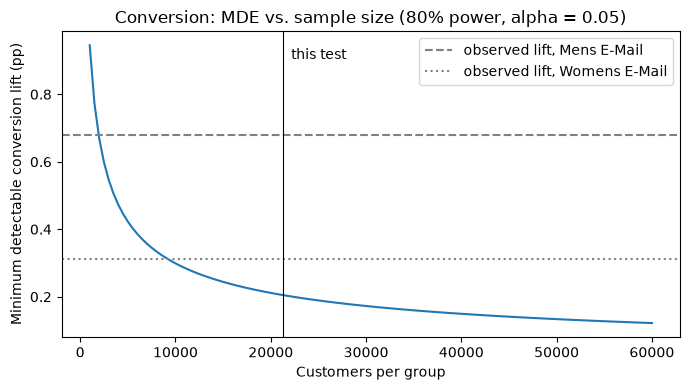

In [5]:
p0_conv = ctrl["conversion"].mean()
n_grid = np.linspace(1_000, 60_000, 120).astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_grid, [su.mde_two_proportions(p0_conv, n) * 100 for n in n_grid])
for arm, ls in zip(data.TREATMENTS, ["--", ":"]):
    lift = (df.loc[df["segment"] == arm, "conversion"].mean() - p0_conv) * 100
    ax.axhline(lift, ls=ls, color="grey", label=f"observed lift, {arm}")
ax.axvline(n_per_group, color="black", lw=0.8)
ax.text(n_per_group, ax.get_ylim()[1] * 0.95, "  this test", va="top")
ax.set_xlabel("Customers per group")
ax.set_ylabel("Minimum detectable conversion lift (pp)")
ax.set_title("Conversion: MDE vs. sample size (80% power, alpha = 0.05)")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# Sample size a follow-up test would need per group, for a range of conversion lifts
pd.DataFrame({
    "target_lift_pp": [0.10, 0.20, 0.30, 0.50],
    "n_per_group_needed": [su.n_per_group_two_proportions(p0_conv, l / 100) for l in [0.10, 0.20, 0.30, 0.50]],
})

,target_lift_pp,n_per_group_needed
0,0.1000,97124
1,0.2000,26215
2,0.3000,12509
3,0.5000,5119


**Implication for section 3:** a segment with, say, 5,000 customers per arm has a much larger MDE than the full test. Segment results for conversion will therefore be noisy; visit (higher base rate) and spend are more informative at segment level.

*Interpretation (fill in):* …

## 3 · Segment-level (heterogeneous) effects

For each pre-treatment segment, the lift of each e-mail vs. control in **visit** and **spend per customer**.

⚠️ This is **exploratory**: many comparisons are made, so isolated "significant" results should be treated as hypotheses for a follow-up test, not as conclusions.

In [7]:
segment_vars = ["past_purchase", "customer_type", "channel", "zip_code"]
seg_rows = []
for var in segment_vars:
    for level, g in df.groupby(var):
        g_ctrl = g[g["segment"] == data.CONTROL]
        for arm in data.TREATMENTS:
            g_t = g[g["segment"] == arm]
            v = su.diff_in_proportions(g_t["visit"], g_ctrl["visit"])
            s = su.diff_in_means(g_t["spend"], g_ctrl["spend"])
            seg_rows.append({"segment_var": var, "level": level, "arm": arm,
                             "n_treat": len(g_t), "n_ctrl": len(g_ctrl),
                             "visit_lift": v["abs_lift"], "visit_ci_low": v["ci_low"], "visit_ci_high": v["ci_high"],
                             "spend_lift": s["diff"], "spend_se": s["se"],
                             "spend_ci_low": s["ci_low"], "spend_ci_high": s["ci_high"],
                             "revenue_per_1000_emails": s["diff"] * 1000})
segments = pd.DataFrame(seg_rows)
segments[["segment_var", "level", "arm", "n_treat", "visit_lift", "spend_lift",
          "spend_ci_low", "spend_ci_high", "revenue_per_1000_emails"]]

,segment_var,level,arm,n_treat,visit_lift,spend_lift,spend_ci_low,spend_ci_high,revenue_per_1000_emails
0,past_purchase,Both,Mens E-Mail,2181,0.1344,1.8250,0.4902,3.1598,"1,824.9864"
1,past_purchase,Both,Womens E-Mail,2118,0.0711,0.1619,-0.8133,1.1371,161.8812
2,past_purchase,Mens only,Mens E-Mail,9558,0.0692,0.6827,0.2472,1.1183,682.7353
3,past_purchase,Mens only,Womens E-Mail,9622,0.0111,0.2784,-0.1236,0.6803,278.3545
4,past_purchase,Womens only,Mens E-Mail,9568,0.0706,0.6157,0.2697,0.9618,615.7308
5,past_purchase,Womens only,Womens E-Mail,9647,0.0740,0.6316,0.2951,0.9682,631.6480
6,customer_type,Existing,Mens E-Mail,10621,0.0778,0.5780,0.1416,1.0143,577.9669
7,customer_type,Existing,Womens E-Mail,10624,0.0401,0.1140,-0.2755,0.5034,113.9571
8,customer_type,New,Mens E-Mail,10686,0.0753,0.9600,0.5938,1.3262,960.0198
9,customer_type,New,Womens E-Mail,10763,0.0504,0.7323,0.4012,1.0634,732.2878


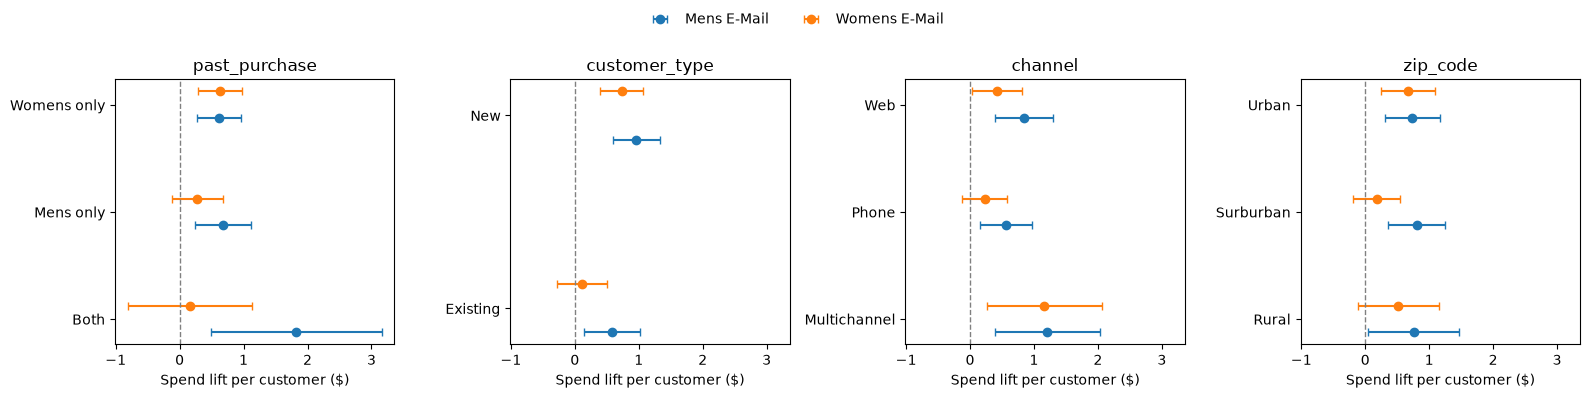

In [8]:
fig, axes = plt.subplots(1, len(segment_vars), figsize=(16, 4), sharex=True)
colors = {"Mens E-Mail": "tab:blue", "Womens E-Mail": "tab:orange"}
for ax, var in zip(axes, segment_vars):
    sub = segments[segments["segment_var"] == var]
    levels = sorted(sub["level"].unique())
    for j, arm in enumerate(data.TREATMENTS):
        s = sub[sub["arm"] == arm].set_index("level").loc[levels]
        y = np.arange(len(levels)) + (j - 0.5) * 0.25
        ax.errorbar(s["spend_lift"], y,
                    xerr=[s["spend_lift"] - s["spend_ci_low"], s["spend_ci_high"] - s["spend_lift"]],
                    fmt="o", capsize=3, color=colors[arm], label=arm)
    ax.axvline(0, color="grey", ls="--", lw=1)
    ax.set_yticks(np.arange(len(levels)), levels)
    ax.set_title(var)
    ax.set_xlabel("Spend lift per customer ($)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

### 3b · Is the difference between segments real?

The key business question: does the men's e-mail also work for customers who only bought **women's** products before, and vice versa? A z-test on the difference of two lifts answers this (an interaction test).

In [9]:
pp = segments[segments["segment_var"] == "past_purchase"].set_index(["arm", "level"])
tests = []
for arm in data.TREATMENTS:
    levels = [l for l in ["Mens only", "Womens only", "Both"] if (arm, l) in pp.index]
    for i in range(len(levels)):
        for j in range(i + 1, len(levels)):
            a, b = pp.loc[(arm, levels[i])], pp.loc[(arm, levels[j])]
            res = su.diff_of_lifts(a["spend_lift"], a["spend_se"], b["spend_lift"], b["spend_se"])
            tests.append({"arm": arm, "comparison": f"{levels[i]} vs {levels[j]}", **res})
interaction = pd.DataFrame(tests)
interaction["p_holm"] = su.holm_adjust(interaction["p_value"].tolist())
interaction

,arm,comparison,diff,se,z,p_value,p_holm
0,Mens E-Mail,Mens only vs Womens only,0.0670,0.2838,0.2361,0.8134,1.0000
1,Mens E-Mail,Mens only vs Both,-1.1423,0.7164,-1.5945,0.1108,0.5542
2,Mens E-Mail,Womens only vs Both,-1.2093,0.7036,-1.7188,0.0857,0.5139
3,Womens E-Mail,Mens only vs Womens only,-0.3533,0.2675,-1.3210,0.1865,0.7460
4,Womens E-Mail,Mens only vs Both,0.1165,0.5382,0.2164,0.8287,1.0000
5,Womens E-Mail,Womens only vs Both,0.4698,0.5264,0.8925,0.3721,1.0000


## 4 · Findings

- **CUPED:** Variance reduction was negligible (≤ 0.4% with past-year spend, ≤ 3% with all pre-treatment covariates). This matches the theoretical ceiling: past spend explains < 0.5% of the variance in 2-week outcomes, which are rare binary events. Point estimates were unchanged across methods, so the raw results from notebook 01 are robust.
- **Power:** With ~21,300 customers per arm the test could detect a 0.84 pp lift in visits and a 0.20 pp lift in conversion. Both observed visit lifts and the men's conversion lift are far above this; the women's conversion lift (0.31 pp) is only ~1.5× the MDE. Segments with fewer than ~9,000 customers per arm cannot reliably detect a conversion effect of that size.
- **Segments:** The men's e-mail increased spend in **every** segment. The women's e-mail worked for women-only buyers, new customers and web/multichannel customers, but its effect was not distinguishable from zero for men-only buyers, existing customers and phone customers.
- **Caution:** Formal interaction tests did not confirm differences between past-purchase segments (all Holm-adjusted p > 0.5). The strongest signal — the women's e-mail working for new but not existing customers (unadjusted p ≈ 0.02) — is exploratory and should be validated in a follow-up test.

**Next notebook (03):** turn the segment results into a targeting rule (who gets which e-mail, or none), estimate the incremental revenue of that rule vs. "send men's e-mail to everyone", and write the one-page memo.